# DEFI 1 : Prédiction de la survenue d'une bactériémie
**Groupe 2 :**
- **SAOUDI Lydia**
- **NKRUMAH-BUADII Cornelius**
- **LEYENBERGER Emma**
- **ENGIN Belfin**
- **HUANG Flora**
- **LAMLOUH Awataf**

### Contexte et objectif
Dans le cadre du Défi 1, l'objectif est de développer et de valider un modèle d'apprentissage automatique capable de prédire la survenue d'une bactériémie chez un patient (1 = oui / 0 = non).
Les données viennent du fichier `bacteriemie.csv.gz` : 11 753 observations collectées entre janvier 2006 et décembre 2010 à l'Hôpital général de Vienne, auprès de patients présentant une suspicion clinique d'infection.

### Méthodologie
1. Chargement et nettoyage de base
2. Séparation train / test (stratifiée)
3. Préparation des données (pré-traitement)
4. Choix des modèles : régression logistique (baseline), Random Forest, HistGradientBoosting, LightGBM
   - métriques : F1-score, puis précision
   - validation croisée et comparaison (tableau et histogramme)
5. Optimisation des hyperparamètres (RandomizedSearchCV)
6. Stacking (SuperLearner)
7. Optimisation du seuil de décision (sur les prédictions de validation croisée)  
8. Évaluation finale sur le test 
9. Conlusion

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import warnings

os.environ["LOKY_MAX_CPU_COUNT"] = "4" # pour évite un message d'avertissement sous Windows

# 1. Chargement et nettoyage du jeu de données

Avant d'entamer l'entraînement des données, nous allons, dans un premier temps, analyser et nettoyer notre jeu de donnés.

In [2]:
df = pd.read_csv('bacteriemie.csv.gz', na_values=['NA'])
pd.set_option('display.max_columns', None)
df.head(10)

,ID,SEX,AGE,MCV,HGB,HCT,PLT,MCH,MCHC,RDW,MPV,LYM,MONO,EOS,BASO,NT,APTT,FIB,SODIUM,POTASS,CA,PHOS,MG,CREA,BUN,HS,GBIL,TP,ALB,AMY,PAMY,LIP,CHE,AP,ASAT,ALAT,GGT,LDH,CK,GLU,TRIG,CHOL,CRP,BASOR,EOSR,LYMR,MONOR,NEU,NEUR,PDW,RBC,WBC,BloodCulture
0,1,2,62,99.3,11.5,35.9,307.0,31.5,31.8,19.5,10.8,0.4,1.7,0.0,0.1,86.0,28.8,578.0,137.0,3.88,2.29,1.20,0.66,0.65,5.7,5.3,0.59,67.0,36.7,30.0,16.0,10.0,5.12,85.0,22.0,14.0,48.0,284.0,23.0,107.0,105.0,175.0,3.94,0.413223,0.000000,1.652893,7.024793,22.0,90.909091,10.6,3.7,24.10,no
1,3,1,72,85.1,10.3,34.7,182.0,26.0,30.6,15.0,9.7,0.4,0.2,0.1,0.0,90.0,29.8,NaN,141.0,NaN,2.21,0.58,NaN,0.76,19.9,NaN,0.48,65.3,37.4,NaN,NaN,NaN,5.61,80.0,28.0,25.0,61.0,NaN,36.0,84.0,NaN,NaN,1.42,0.000000,0.826446,3.305785,1.652893,11.4,94.214876,11.4,3.9,12.17,no
2,5,1,46,96.3,7.4,22.8,64.0,31.2,32.4,19.7,11.1,1.5,1.2,0.1,0.1,58.0,36.3,313.0,147.0,4.61,1.92,1.51,1.03,1.25,50.6,NaN,8.42,40.5,22.1,146.0,NaN,89.0,2.52,119.0,124.0,135.0,134.0,696.0,40.0,107.0,NaN,NaN,12.09,0.568182,0.568182,8.522727,6.818182,14.7,83.522727,14.1,2.5,17.45,no
3,9,2,38,85.1,13.7,38.7,183.0,30.2,35.3,12.6,10.0,0.8,0.4,0.0,0.0,95.0,33.1,490.0,137.0,NaN,2.34,0.97,0.74,0.65,8.5,3.0,0.42,78.4,43.8,84.0,50.0,50.0,6.91,108.0,35.0,22.0,72.0,NaN,79.0,93.0,152.0,167.0,11.17,0.000000,0.000000,8.333333,4.166667,8.4,87.500000,12.2,4.4,9.86,no
4,10,1,68,104.5,15.7,46.9,144.0,34.8,33.5,13.9,10.9,2.2,0.9,0.1,0.0,61.0,41.8,400.0,141.0,4.41,2.08,0.99,0.56,0.82,15.3,5.5,2.40,57.5,30.1,95.0,57.0,25.0,6.79,68.0,32.0,11.0,68.0,263.0,75.0,89.0,85.0,144.0,5.89,0.000000,1.000000,22.000000,9.000000,6.8,68.000000,12.9,4.3,9.94,no
5,12,1,55,77.0,10.8,34.8,38.0,23.8,30.5,16.8,NaN,0.4,0.1,0.1,0.0,93.0,36.3,413.0,142.0,4.67,2.31,1.16,0.87,1.77,29.8,6.2,0.45,70.8,43.6,177.0,43.0,30.0,7.40,153.0,26.0,32.0,96.0,181.0,87.0,96.0,129.0,156.0,1.29,0.000000,5.555556,22.222222,5.555556,1.2,66.666667,NaN,4.7,1.78,no
6,19,2,52,83.0,10.3,30.1,105.0,28.6,34.1,13.2,11.3,0.9,0.9,0.3,0.1,69.0,28.1,407.0,136.0,3.80,1.92,0.72,0.53,0.58,14.0,4.0,2.46,53.8,24.8,35.0,35.0,38.0,2.64,146.0,97.0,156.0,192.0,277.0,87.0,104.0,207.0,123.0,3.80,1.666667,5.000000,15.000000,15.000000,3.8,63.333333,13.2,3.5,5.98,no
7,21,1,47,86.5,9.1,28.0,216.0,28.3,32.9,15.7,10.9,0.7,0.6,0.0,0.1,108.0,28.5,604.0,131.0,5.28,2.04,1.28,0.82,1.02,18.6,4.0,3.21,60.2,26.2,79.0,63.0,52.0,2.61,180.0,24.0,63.0,266.0,221.0,30.0,104.0,292.0,194.0,3.04,1.041667,0.000000,7.291667,6.250000,8.2,85.416667,12.0,3.3,9.45,no
8,23,2,59,100.7,10.0,31.0,92.0,32.6,32.4,19.7,11.2,0.9,0.3,0.0,0.0,93.0,43.6,369.0,137.0,4.31,2.28,1.90,0.95,1.15,77.1,5.8,0.98,57.9,29.6,25.0,15.0,14.0,2.71,74.0,25.0,27.0,66.0,245.0,17.0,161.0,126.0,205.0,1.39,0.000000,0.000000,52.941176,17.647059,0.5,29.411765,13.8,3.1,1.41,no
9,25,2,51,85.4,8.8,25.6,20.0,28.9,33.6,15.1,9.6,0.2,0.1,0.0,0.0,83.0,NaN,533.0,135.0,3.21,2.16,0.98,0.71,0.54,7.4,2.9,1.69,58.2,33.0,32.0,20.0,26.0,4.18,219.0,31.0,53.0,131.0,258.0,13.0,122.0,319.0,117.0,11.71,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,no


In [3]:
df.shape

(11753, 53)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11753 entries, 0 to 11752
Data columns (total 53 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   ID            11753 non-null  int64  
 1   SEX           11753 non-null  int64  
 2   AGE           11753 non-null  int64  
 3   MCV           11716 non-null  float64
 4   HGB           11716 non-null  float64
 5   HCT           11716 non-null  float64
 6   PLT           11715 non-null  float64
 7   MCH           11716 non-null  float64
 8   MCHC          11716 non-null  float64
 9   RDW           11702 non-null  float64
 10  MPV           11188 non-null  float64
 11  LYM           11541 non-null  float64
 12  MONO          11559 non-null  float64
 13  EOS           11639 non-null  float64
 14  BASO          11632 non-null  float64
 15  NT            9774 non-null   float64
 16  APTT          9701 non-null   float64
 17  FIB           9688 non-null   float64
 18  SODIUM        10711 non-nu

In [5]:
# Vérifier si les NA textuels sont convertis en NaN
df.isna().sum().sort_values(ascending=False)

PAMY            5647
TRIG            4053
CHOL            4039
GLU             3361
AMY             3102
LIP             2925
HS              2468
FIB             2065
APTT            2052
NT              1979
CHE             1974
CK              1661
POTASS          1606
MG              1513
LDH             1358
ALB             1343
TP              1282
GBIL            1151
AP              1125
SODIUM          1042
CA              1029
GGT             1010
PHOS             997
ASAT             920
PDW              889
ALAT             788
NEUR             592
EOSR             592
LYMR             592
MONOR            592
BASOR            592
NEU              588
MPV              565
WBC              377
RBC              375
LYM              212
MONO             194
BUN              136
CREA             124
CRP              122
BASO             121
EOS              114
RDW               51
PLT               38
HGB               37
MCV               37
MCHC              37
MCH          

In [6]:
# Doublon ID
df["ID"].duplicated().any()

np.False_

In [7]:
# Vérifier si les âges sont cohérents
df['AGE'].describe().round()

count    11753.0
mean        56.0
std         18.0
min         16.0
25%         43.0
50%         58.0
75%         70.0
max        101.0
Name: AGE, dtype: float64

In [8]:
df['BloodCulture'].value_counts()

BloodCulture
no     10809
yes      944
Name: count, dtype: int64

In [9]:
(df['BloodCulture'].value_counts(normalize=True) * 100).round(2)

BloodCulture
no     91.97
yes     8.03
Name: proportion, dtype: float64

### Variable cible `BloodCulture`

Environ 8 % des patients ont une bactériémie : les classes sont déséquilibrées -> on applique une binarisation :
- no = 0 (pas de bactériémie)
- yes = 1 (présence de bactériémie)

In [10]:
df["BloodCulture"] = df["BloodCulture"].map({"no": 0, "yes": 1})
assert df["BloodCulture"].isna().sum() == 0
df["BloodCulture"].value_counts()

BloodCulture
0    10809
1      944
Name: count, dtype: int64

### Création de variables cliniques

Nous ajoutons deux variables calculées à partir des données existantes. Ces ratios transforment des valeurs biologiques brutes en indicateurs cliniques aidant le modèle à mieux prédire les cas de bactériémie.

- **`RATIO_CAR`** : rapport entre la protéine C-réactive (`CRP`) et l'albumine (`ALB`).

- **`RATIO_NLR`** : rapport entre les neutrophiles (`NEU`) et les lymphocytes (`LYM`).

Pour `RATIO_CAR`, nous ajoutons `1e-4` au dénominateur pour éviter une division par zéro.

Pour `RATIO_NLR`, ce n'est pas suffisant : 90 patients ont 0 lymphocyte (`LYM = 0`, code cellule 13), ce qui donnait des valeurs extrêmes (maximum de 354 000 pour une médiane de 6,9). Nous fixons donc un **plancher de 0,1** sur les lymphocytes (leur mesure est donnée à 0,1 près). Le ratio ne peut ainsi plus dépasser 10 fois le nombre de neutrophiles.

In [11]:
def add_clinical_features(data):
    df_feat = data.copy()

    # 1. CRP / Albumine (CAR) : inflammation
    if 'CRP' in df_feat.columns and 'ALB' in df_feat.columns:
        df_feat['RATIO_CAR'] = df_feat['CRP'] / (df_feat['ALB'] + 1e-4)

    # 2. Neutrophiles / Lymphocytes (NLR) : réponse immunitaire
    # Plancher de 0,1 sur les lymphocytes : évite les valeurs extrêmes quand LYM = 0
    if 'NEU' in df_feat.columns and 'LYM' in df_feat.columns:
        df_feat['RATIO_NLR'] = df_feat['NEU'] / df_feat['LYM'].clip(lower=0.1)
    return df_feat

df = add_clinical_features(df)

In [12]:
df.groupby('BloodCulture')[['CRP', 'ALB', 'NEU', 'LYM']].median().round(2)

,CRP,ALB,NEU,LYM
BloodCulture,,,,
0,8.40,33.60,7.25,1.1
1,11.72,32.05,8.30,0.7


In [13]:
# Vérification : plus de valeurs extrêmes pour les ratios (regarde surtout la ligne "max")
print("Patients avec LYM = 0 :", (df['LYM'] == 0).sum())
print("Plus petite valeur de LYM :", df['LYM'].min())

df[['RATIO_CAR', 'RATIO_NLR']].describe().round(1)

Patients avec LYM = 0 : 90
Plus petite valeur de LYM : 0.0


,RATIO_CAR,RATIO_NLR
count,10350.0,11165.0
mean,0.4,10.8
std,0.4,14.8
min,0.0,0.0
25%,0.1,3.8
50%,0.3,6.9
75%,0.6,12.5
max,3.1,354.0


**Pourquoi ces variables ?**

Pour repérer une bactériémie, nous avons choisi des ratios qui reflètent : l'**inflammation** du corps et la **réponse immunitaire**. Un ratio compare deux mesures. Dans notre cas, il met en évidence l'écart entre un patient non bactériémique et un patient bactériémique. Les médianes du tableau ci-dessus permettent de le vérifier.

- **`RATIO_CAR`** (CRP / albumine) : lors d'une infection bactérienne, la CRP, protéine produite par le foie en cas d'inflammation, augmente fortement, tandis que l'albumine baisse (de 33,6 à 32 G/L d'après le tableau). Le ratio monte quand l'inflammation est forte.

- **`RATIO_NLR`** (neutrophiles / lymphocytes) : face à une bactérie, les neutrophiles, première ligne de défense de l'organisme, augmentent, alors que les lymphocytes chutent (médiane de 1,1 à 0,7 G/L d'après le tableau). Le ratio monte avec le stress infectieux. La chute des lymphocytes s'explique par le sepsis. Quand les lymphocytes sont à 0, le ratio deviendrait extrême : nous utilisons donc un plancher de 0,1 au dénominateur.

Références :
- https://www.msdmanuals.com/fr/accueil/infections/bact%C3%A9ri%C3%A9mie-septic%C3%A9mie-et-choc-septique/introduction-%C3%A0-la-bact%C3%A9ri%C3%A9mie-%C3%A0-la-septic%C3%A9mie-et-au-choc-septique
- https://www.infectiologie.com/UserFiles/File/pilly-etudiant/items-edition-2023/pilly-2023-item-157.pdf

# 2. Data splitting (train / test)

Nous séparons la variable à prédire ($y$) des variables explicatives ($X$).<br>
Nous retirons deux colonnes :
- `ID` : un identifiant qui n'apporte aucune information utile ;
- `BloodCulture` : c'est la réponse, elle fausserait l'évaluation.

Puis nous divisons les données en deux sets:
- **train (80 %)** : pour entraîner nos modèles ;
- **test (20 %)** : pour l'évaluation finale, on n'y touche pas.

Nous appliquons aussi une séparation stratifiée pour que la proportion de patients présentant une bactériémie reste identique entre les deux set de données.

In [14]:
from sklearn.model_selection import train_test_split

# Séparer les variables explicatives (X) et la cible (y)
y = df['BloodCulture']
X = df.drop(['BloodCulture', 'ID'], axis=1)

# Division en 2 sets : entraînement et test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, shuffle=True, random_state=42)

variables_catégorielles = ['SEX']
variables_quantitatives = X_train.columns.difference(variables_catégorielles).tolist()

In [15]:
X_train.shape

(9402, 53)

In [16]:
X_test.shape

(2351, 53)

In [17]:
y_train.value_counts()

BloodCulture
0    8647
1     755
Name: count, dtype: int64

In [18]:
y_test.value_counts()

BloodCulture
0    2162
1     189
Name: count, dtype: int64

# 3. Préparation des données

Caractéristiques de nos données :
- taille moyenne (11 753 patients) ;
- données tabulaires, surtout numériques ;
- beaucoup de valeurs manquantes, réparties de façon inégale ;
- classes déséquilibrées (environ 8 % de cas positifs) ;
- métriques d'évaluation : F1-score, puis précision.

Pour rendre les données utilisables par les modèles, on applique :
- **SimpleImputer** (médiane) : impute les valeurs manquantes numériques par la médiane de la colonne ;
- **StandardScaler** : met les variables numériques à la même échelle (moyenne 0, écart-type 1) ;
- **SimpleImputer** : remplace les valeurs manquantes par la valeur la plus fréquente ;
- **OneHotEncoder** : transforme `SEX` en colonnes 0 / 1.

Tout est regroupé dans un Pipeline : les transformations sont apprises uniquement sur les données d'entraînement, ce qui évite que le test influence le modèle.

In [19]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

In [20]:
# Variables numériques : imputation puis mise à l'échelle
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Variable catégorielle (SEX) : imputation puis encodage en 0 / 1
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy="most_frequent")),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Assemblage : chaque transformation est appliquée à ses variables
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, variables_quantitatives),
        ('cat', categorical_transformer, variables_catégorielles)
    ]
)

# 4. Modèles

Choix des modèles (classification) :
- **Régression logistique (baseline)** : modèle simple et rapide, qui sert de point de comparaison.
- **Random Forest** : il capte les relations non linéaires et les interactions entre variables, et il est peu sensible aux valeurs extrêmes. Il est efficace sur des données tabulaires de taille moyenne comme les nôtres.
- **HistGradientBoosting** : les arbres sont construits l'un après l'autre, chacun corrigeant les erreurs du précédent. Il gère directement les valeurs manquantes, très nombreuses dans nos données.
- **LightGBM** : même principe que HistGradientBoosting, avec plus de paramètres de réglage. Il gère aussi les valeurs manquantes et le déséquilibre des classes.

Ces modèles seront ensuite combinés par stacking.

In [21]:
from sklearn.linear_model import LogisticRegression
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

# class_weight='balanced' : donne plus de poids aux cas positifs, qui sont rares
# ici chaque modèle est précédé du préprocessing dans un même Pipeline

scale_pos_weight = (len(y_train) - sum(y_train)) / sum(y_train)

models = {
    'LogReg': Pipeline([
        ('prep', preprocessor),
        ('clf', LogisticRegression(class_weight='balanced', C=0.1, max_iter=1000, random_state=42)),
    ]),
    'RandomForest': Pipeline([
        ('prep', preprocessor),
        ('clf', RandomForestClassifier(class_weight='balanced_subsample', n_estimators=300, max_depth=12, random_state=42, n_jobs=-1)),
    ]),
    'HistGB': Pipeline([
        ('prep', preprocessor),
        ('clf', HistGradientBoostingClassifier(class_weight='balanced', max_iter=200, learning_rate=0.03, max_leaf_nodes=31, random_state=42)),
    ]),
    'LightGBM': Pipeline([
        ('prep', preprocessor),
        ('clf', LGBMClassifier(scale_pos_weight=scale_pos_weight, n_estimators=300, learning_rate=0.03, num_leaves=31, random_state=42, verbose=-1, n_jobs=-1)),
    ]),
}

### Entraînement et prédiction par validation croisée

Pour comparer les modèles sans toucher au test, nous utilisons une validation croisée à 5 parties sur le train : le modèle est entraîné sur 4 parties et prédit la 5eme, puis on recommence pour chaque partie. Chaque patient est ainsi prédit par un modèle qui ne l'a jamais vu. Cela permet d'éviter l'overfitting et le data leakage, tout en obtenant une estimation fiable et réaliste des performances de nos modèles.

Le résultat est une probabilité de bactériémie pour chaque patient.

In [22]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import f1_score, precision_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

### Choix du seuil de décision

Un modèle donne une probabilité. Pour décider s'il y a une bactériémie ou non, nous comparons cette probabilité à un seuil : au-dessus du seuil, nous prédissons une bactériémie.

Le seuil habituel est 0.5 (par défaut), mais il convient mal quand les cas positifs sont rares. La fonction ci-dessous va permettre de tester tous les seuils de 0.01 à 0.99 et garde celui qui donne le meilleur F1-score.

In [23]:
seuils = np.linspace(0.01, 0.99, 99)

def meilleur_seuil(y, proba):
    # F1 obtenu pour chaque seuil testé
    f1_par_seuil = [f1_score(y, (proba >= t).astype(int), zero_division=0) for t in seuils]

    # Nous gardons le seuil au meilleur F1, et nous calculons la précision avec ce seuil
    seuil = seuils[np.argmax(f1_par_seuil)]
    precision = precision_score(y, (proba >= seuil).astype(int), zero_division=0)
    return seuil, max(f1_par_seuil), precision

In [24]:
results = {}

for name, pipe in models.items():
    # Probabilité de bactériémie de chaque patient, prédite par validation croisée
    proba = cross_val_predict(pipe, X_train, y_train, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]

    # F1 avec le seuil habituel (0.5), puis avec le meilleur seuil
    f1_05 = f1_score(y_train, (proba >= 0.5).astype(int), zero_division=0)
    seuil, f1_best, precision = meilleur_seuil(y_train, proba)

    results[name] = {
        'f1_05': f1_05,
        'best_threshold': seuil,
        'f1_best': f1_best,
        'precision': precision,
    }

    print(
        f"{name}: F1 (seuil 0.5) = {f1_05:.3f} | "
        f"F1 (meilleur seuil {seuil:.2f}) = {f1_best:.3f} | "
        f"Précision = {precision:.3f}"
    )

LogReg: F1 (seuil 0.5) = 0.275 | F1 (meilleur seuil 0.72) = 0.329 | Précision = 0.290
RandomForest: F1 (seuil 0.5) = 0.231 | F1 (meilleur seuil 0.31) = 0.331 | Précision = 0.264
HistGB: F1 (seuil 0.5) = 0.325 | F1 (meilleur seuil 0.51) = 0.326 | Précision = 0.269
LightGBM: F1 (seuil 0.5) = 0.323 | F1 (meilleur seuil 0.50) = 0.323 | Précision = 0.299


In [25]:
# Tableau récapitulatif F1 et précision
results_df = pd.DataFrame(results).T
results_df = results_df[['f1_05', 'best_threshold', 'f1_best', 'precision']]
results_df.round(3)

,f1_05,best_threshold,f1_best,precision
LogReg,0.275,0.72,0.329,0.290
RandomForest,0.231,0.31,0.331,0.264
HistGB,0.325,0.51,0.326,0.269
LightGBM,0.323,0.50,0.323,0.299


Avec le meilleur seuil, les quatre modèles obtiennent un F1 proche (environ 0.32 à 0.33). Ces valeurs servent de référence avant l'optimisation des hyperparamètres.

# 5. Optimisation des hyperparamètres

Les hyperparamètres sont les réglages d'un modèle (nombre d'arbres, profondeur, taux d'apprentissage...). Jusqu'ici, nous avons utilisé les réglages par défaut. Nous cherchons maintenant des réglages plus performants.
-> Le choix des paramètres se fait, dans un premier temps par défaut, puis manuellement.

- **Méthode** : `RandomizedSearchCV` : permet de tester des combinaisons de réglages tirées dans les grilles ci-dessous (20 au maximum par modèle). Chaque combinaison est évaluée par validation croisée sur le set train.
- **Objectif** : maximiser le **F1-score** puis, à F1 égal, la **précision**.

In [26]:
param_grids = {
    'LogReg': {
    'clf__C': [0.01,0.05,0.1,1,10], # clf__ = réglage du modèle dans le Pipeline
},
    'RandomForest': {
        'clf__n_estimators': [205, 210, 220, 230],
        'clf__max_depth': [None, 5, 10, 20],
        'clf__min_samples_leaf': [5, 6, 7],
    },
    'HistGB': {
        'clf__learning_rate': [0.05, 0.06, 0.07],
        'clf__max_iter': [90, 100, 110, 120],
        'clf__max_leaf_nodes': [60, 63, 64, 65],
        'clf__min_samples_leaf': [20, 50, 100],
        'clf__l2_regularization': [0, 1, 10], # pénalise les modèles trop complexes
    },
    'LightGBM': {
        'clf__scale_pos_weight': [scale_pos_weight],
        'clf__n_estimators': [200, 300, 500],
        'clf__learning_rate': [0.01, 0.02, 0.03],
        'clf__num_leaves': [15,31,63],
    },
}

### 5.1 Les notes pour comparer les combinaisons

Chaque combinaison reçoit deux notes : le F1 et la précision, calculées au meilleur seuil (grâce à la fonction `meilleur_seuil`). Sans cela, les modèles seraient comparés avec le seuil 0.5.

In [27]:
from sklearn.base import clone
from sklearn.model_selection import RandomizedSearchCV, ParameterGrid

def note_f1(modele, X, y):
    proba = modele.predict_proba(X)[:, 1]
    return meilleur_seuil(y, proba)[1]

def note_precision(modele, X, y):
    proba = modele.predict_proba(X)[:, 1]
    return meilleur_seuil(y, proba)[2]

### 5.2 Recherche des meilleurs hyperparamètres

Pour chaque modèle : nous testons les combinaisons puis nous gardons celle qui a le meilleur F1 (puis la meilleure précision), et nous entraînons le modèle avec cette combinaison.

In [28]:
best_models = {}   # modèles réglés avec leurs meilleurs hyperparamètres
best_params = {}   # meilleurs hyperparamètres de chaque modèle

for name, pipe in models.items():
    # "memory" garde le préprocessing en mémoire pour aller plus vite
    pipe_rapide = clone(pipe).set_params(memory='cache_preproc')
    n_essais = min(20, len(ParameterGrid(param_grids[name])))

    # Tester les combinaisons d'hyperparamètres
    recherche = RandomizedSearchCV(
        pipe_rapide, param_grids[name], n_iter=n_essais, cv=cv, n_jobs=-1, random_state=42,
        scoring={'f1': note_f1, 'precision': note_precision}, refit=False,)
    recherche.fit(X_train, y_train)

    # Classer les essais : meilleur F1 puis précision
    essais = pd.DataFrame(recherche.cv_results_)
    essais['f1_arrondi'] = essais['mean_test_f1'].round(3)
    meilleur = essais.sort_values(['f1_arrondi', 'mean_test_precision'], ascending=False).iloc[0]

    # Entraîner le modèle avec la meilleure combinaison
    best_models[name] = clone(pipe_rapide).set_params(**meilleur['params']).fit(X_train, y_train)
    best_params[name] = {k.replace('clf__', ''): v for k, v in meilleur['params'].items()}
    print(f"{name} : {best_params[name]}")

LogReg : {'C': 1}
RandomForest : {'n_estimators': 210, 'min_samples_leaf': 5, 'max_depth': 20}
HistGB : {'min_samples_leaf': 100, 'max_leaf_nodes': 65, 'max_iter': 110, 'learning_rate': 0.07, 'l2_regularization': 1}
LightGBM : {'scale_pos_weight': 11.452980132450332, 'num_leaves': 15, 'n_estimators': 200, 'learning_rate': 0.03}


### 5.3 F1-score et précision après optimisation

Nous refaisons le même calcul (probabilités par validation croisée, puis meilleur seuil), mais avec les modèles optimisés.

In [29]:
results_opt = {}

for name, modele in best_models.items():
    proba = cross_val_predict(modele, X_train, y_train, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]
    seuil, f1_best, precision = meilleur_seuil(y_train, proba)
    results_opt[name] = {'best_threshold': seuil, 'f1_best': f1_best, 'precision': precision}

    print(f"{name}: F1 = {f1_best:.3f} (seuil {seuil:.2f}) | Précision = {precision:.3f}")

LogReg: F1 = 0.330 (seuil 0.72) | Précision = 0.290
RandomForest: F1 = 0.348 (seuil 0.29) | Précision = 0.288
HistGB: F1 = 0.343 (seuil 0.39) | Précision = 0.280
LightGBM: F1 = 0.331 (seuil 0.63) | Précision = 0.289


### 5.4 Comparaison avant / après optimisation

In [30]:
avant = pd.DataFrame(results).T
apres = pd.DataFrame(results_opt).T

comparaison = pd.DataFrame({
    'F1 avant': avant['f1_best'],
    'F1 après': apres['f1_best'],
    'Précision avant': avant['precision'],
    'Précision après': apres['precision'],
})
comparaison.round(3)

,F1 avant,F1 après,Précision avant,Précision après
LogReg,0.329,0.330,0.290,0.290
RandomForest,0.331,0.348,0.264,0.288
HistGB,0.326,0.343,0.269,0.280
LightGBM,0.323,0.331,0.299,0.289


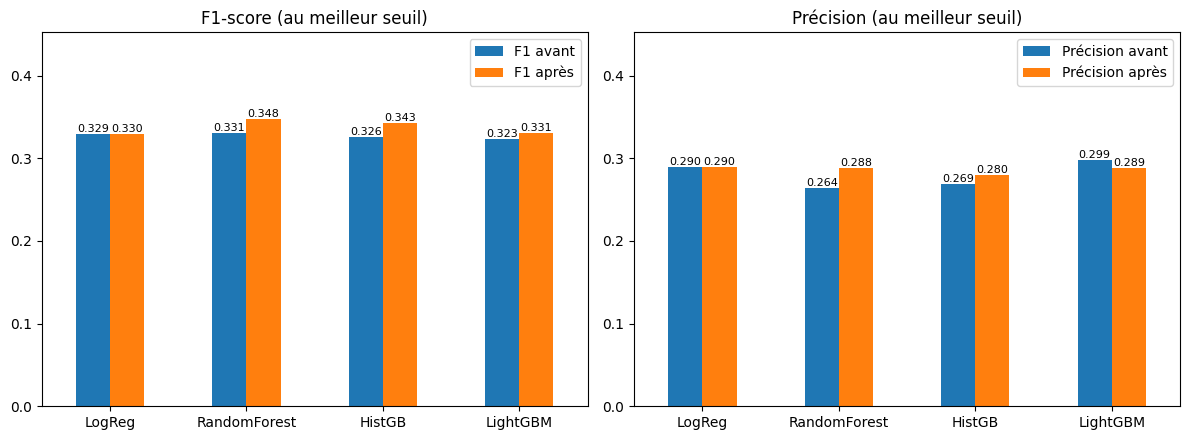

In [31]:
# Histogrammes : F1 et précision, avant / après optimisation
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
comparaison[['F1 avant', 'F1 après']].plot.bar(ax=axes[0], rot=0, title='F1-score (au meilleur seuil)')
comparaison[['Précision avant', 'Précision après']].plot.bar(ax=axes[1], rot=0, title='Précision (au meilleur seuil)')

for ax in axes:
    ax.set_ylim(0, comparaison.max().max() * 1.3)
    for barres in ax.containers:
        ax.bar_label(barres, fmt='%.3f', fontsize=8)
plt.tight_layout()
plt.show()

**Conclusion de l'optimisation**
- Le F1 progresse légèrement pour, LogReg (0.329 -> 0.330), la RF (0.331 -> 0.348), HistGB (0.326 -> 0.343) et LightGBM (0.323 -> 0.331).
- La précision augmente pour le RF et HistGB, mais baisse un peu pour la régression logistique et le LightGBM.
- Les gains restent modestes : les quatre modèles ont des scores proches (F1 entre 0.32 et 0.348).
- Ces scores sont calculés par validation croisée sur le train. Seul le test final donnera le résultat définitif.

# 6. Stacking (SuperLearning)

Le stacking va nous permettre de combiner les 4 modèles optimisés. Chaque modèle donne sa probabilité de bactériémie, puis un modèle final (régression logistique) apprend comment les combiner nous donner un meilleur résultat (fiable).

In [32]:
from sklearn.ensemble import StackingClassifier
import warnings
warnings.filterwarnings("ignore")
os.environ["PYTHONWARNINGS"] = "ignore"

stacking = StackingClassifier(
    estimators=[(name, pipe) for name, pipe in best_models.items()],
    final_estimator=LogisticRegression(class_weight='balanced', C=0.08, max_iter=1000, random_state=42),
    cv=cv,
    stack_method='predict_proba',
    n_jobs=-1
)

stacking.fit(X_train, y_train)

,"estimators estimators: list of (str, estimator)Base estimators which will be stacked together. Each element of thelist is defined as a tuple of string (i.e. name) and an estimatorinstance. An estimator can be set to 'drop' using `set_params`.The type of estimator is generally expected to be a classifier.However, one can pass a regressor for some use case (e.g. ordinalregression).","[('LogReg', ...), ('RandomForest', ...), ...]"
,"final_estimator final_estimator: estimator, default=NoneA classifier which will be used to combine the base estimators.The default classifier is a:class:`~sklearn.linear_model.LogisticRegression`.",LogisticRegre...ndom_state=42)
,"cv cv: int, cross-validation generator, iterable, or ""prefit"", default=NoneDetermines the cross-validation splitting strategy used in`cross_val_predict` to train `final_estimator`. Possible inputs forcv are:* None, to use the default 5-fold cross validation,* integer, to specify the number of folds in a (Stratified) KFold,* An object to be used as a cross-validation generator,* An iterable yielding train, test splits,* `""prefit""`, to assume the `estimators` are prefit. In this case, the estimators will not be refitted.For integer/None inputs, if the estimator is a classifier and y iseither binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used.In all other cases, :class:`~sklearn.model_selection.KFold` is used.These splitters are instantiated with `shuffle=False` so the splitswill be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here.If ""prefit"" is passed, it is assumed that all `estimators` havebeen fitted already. The `final_estimator_` is trained on the `estimators`predictions on the full training set and are **not** cross validatedpredictions. Please note that if the models have been trained on the samedata to train the stacking model, there is a very high risk of overfitting... versionadded:: 1.1 The 'prefit' option was added in 1.1.. note:: A larger number of split will provide no benefits if the number of training samples is large enough. Indeed, the training time will increase. ``cv`` is not used for model evaluation but for prediction.",StratifiedKFo... shuffle=True)
,"stack_method stack_method: {'auto', 'predict_proba', 'decision_function', 'predict'}, default='auto'Methods called for each base estimator. It can be:* if 'auto', it will try to invoke, for each estimator, `'predict_proba'`, `'decision_function'` or `'predict'` in that order.* otherwise, one of `'predict_proba'`, `'decision_function'` or `'predict'`. If the method is not implemented by the estimator, it will raise an error.",'predict_proba'
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for `fit` of all `estimators`.`None` means 1 unless in a `joblib.parallel_backend` context. -1 meansusing all processors. See :term:`Glossary ` for more details.",-1
,"passthrough passthrough: bool, default=FalseWhen False, only the predictions of estimators will be used astraining data for `final_estimator`. When True, the`final_estimator` is trained on the predictions as well as theoriginal training data.",False
,"verbose verbose: int, default=0Verbosity level.",0
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns

# 7. Seuil du stacking
Comme pour les autres modèles, nous cherchons le meilleur seuil à partir des probabilités obtenues par validation croisée sur le train.

In [33]:
# Probabilités du stacking par validation croisée

proba_stacking = cross_val_predict(stacking, X_train, y_train, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]

# F1 avec le seuil 0.5 / puis avec le meilleur seuil
f1_05 = f1_score(y_train, (proba_stacking >= 0.5).astype(int), zero_division=0)
seuil_stacking, f1_stacking, precision_stacking = meilleur_seuil(y_train, proba_stacking)

print(f"Stacking : F1 (seuil 0.5) = {f1_05:.3f} | "
      f"F1 (meilleur seuil {seuil_stacking:.2f}) = {f1_stacking:.3f} | "
      f"Précision = {precision_stacking:.3f}")

Stacking : F1 (seuil 0.5) = 0.300 | F1 (meilleur seuil 0.69) = 0.348 | Précision = 0.281


In [34]:
# Comparaison avec les modèles optimisés
comparaison_finale = pd.DataFrame(results_opt).T[['best_threshold', 'f1_best', 'precision']]
comparaison_finale.loc['Stacking'] = [seuil_stacking, f1_stacking, precision_stacking]
comparaison_finale.round(3)

,best_threshold,f1_best,precision
LogReg,0.72,0.330,0.290
RandomForest,0.29,0.348,0.288
HistGB,0.39,0.343,0.280
LightGBM,0.63,0.331,0.289
Stacking,0.69,0.348,0.281


Interprétation de la table :
- RF et le stacking ont les meilleurs scores.
- Les écarts entre les modèles sont petits.
- On peut supposer qu'environ 1 patient sur 3 annoncé malade l'est vraiment.

# 7bis. Stacking avec les autres modèles au centre
Même stacking que ci-dessus (les 4 modèles optimisés), mais le modèle central n'est plus la régression logistique : nous testons Random Forest, HistGB et LightGB pour ensuite les comparer. Les réglages sont petits pour éviter l'overfitting.

In [35]:
# Ici le stacking avec la régression logistique (celui d'avant) change de nom
comparaison_finale = comparaison_finale.rename(index={'Stacking': 'Stacking LogReg'})
stackings = {'Stacking LogReg': stacking}

# Modèles testés au centre du stacking
centres = {
    'RandomForest': RandomForestClassifier(n_estimators=200, min_samples_leaf=10, class_weight='balanced', random_state=42),
    'HistGB': HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, class_weight='balanced', random_state=42),
    'LightGBM': LGBMClassifier(n_estimators=100, num_leaves=8, learning_rate=0.05, class_weight='balanced', random_state=42, verbose=-1),
}

In [36]:
for nom, centre in centres.items():
    stack = StackingClassifier(estimators=list(best_models.items()), final_estimator=centre, cv=5, stack_method='predict_proba')

    # Probabilités par validation croisée sur le train, puis meilleur seuil
    proba = cross_val_predict(stack, X_train, y_train, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]
    seuil, f1, precision = meilleur_seuil(y_train, proba)

    # Résultats ajoutés au tableau, puis stacking entraîné sur tout le train
    comparaison_finale.loc[f'Stacking {nom}'] = [seuil, f1, precision]
    stackings[f'Stacking {nom}'] = stack.fit(X_train, y_train)

In [37]:
comparaison_finale.round(3)

,best_threshold,f1_best,precision
LogReg,0.72,0.330,0.290
RandomForest,0.29,0.348,0.288
HistGB,0.39,0.343,0.280
LightGBM,0.63,0.331,0.289
Stacking LogReg,0.69,0.348,0.281
Stacking RandomForest,0.52,0.326,0.282
Stacking HistGB,0.70,0.346,0.287
Stacking LightGBM,0.72,0.340,0.291


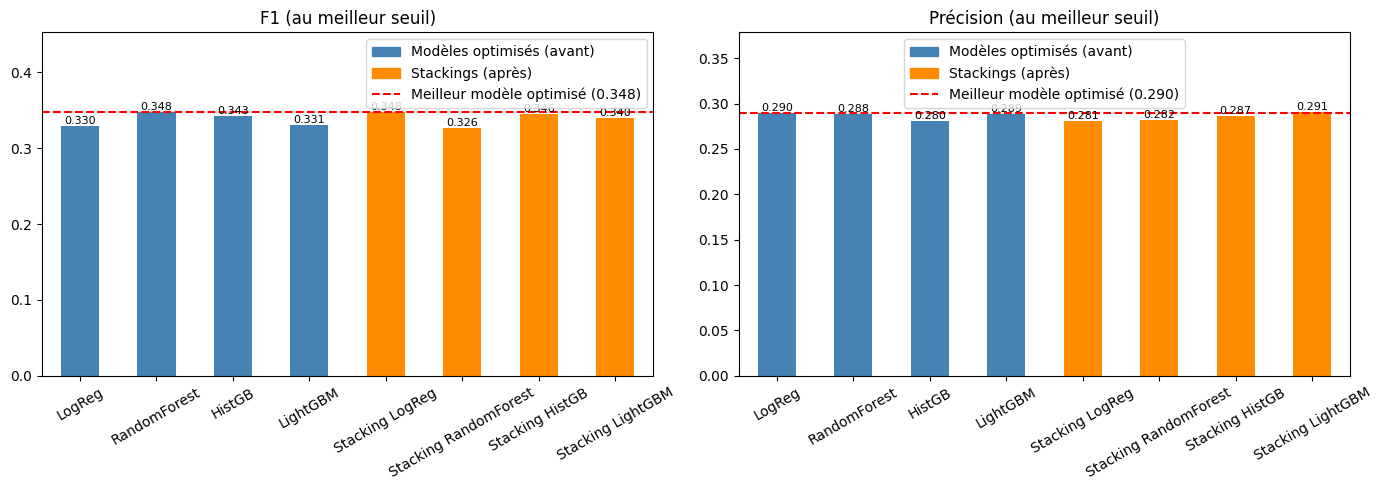

In [38]:
# Figure 2 : comparaison des modèles optimisés (avant) et stackings (après)
from matplotlib.patches import Patch

tableau = comparaison_finale.rename(columns={'f1_best': 'F1', 'precision': 'Précision'})

avant = [nom for nom in tableau.index if not nom.startswith('Stacking')]
couleurs = ['steelblue' if nom in avant else 'darkorange' for nom in tableau.index]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, score in zip(axes, ['F1', 'Précision']):
    tableau[score].plot.bar(ax=ax, color=couleurs, rot=30, title=f'{score} (au meilleur seuil)')
    ax.bar_label(ax.containers[0], fmt='%.3f', fontsize=8)
    ax.set_ylim(0, tableau[score].max() * 1.3)

    # Repère : meilleur score parmi les modèles optimisés
    repere = tableau.loc[avant, score].max()
    ligne = ax.axhline(repere, color='red', linestyle='--', label=f'Meilleur modèle optimisé ({repere:.3f})')

    ax.legend(handles=[Patch(color='steelblue', label='Modèles optimisés (avant)'),
                       Patch(color='darkorange', label='Stackings (après)'),
                       ligne])
plt.tight_layout()
plt.show()

Après avoir testé chaque modèle comme modèle final, nous observons que le meilleur choix est le stacking dont le modèle final est la régression logistique pour un résultat plus robuste en F1-score.

# 8. Évaluation finale sur le set de test

Nous comparons les 4 stackings (régression logistique, Random Forest, HistGB et LightGBM au centre) et nous gardons celui qui a le **meilleur F1 sur le train** (validation croisée), puis la meilleure précision en cas d'égalité. Seul ce stacking est évalué sur le test, qu'il n'a jamais vu, avec le seuil choisi sur le train.

In [39]:
# Seuls les stackings sont comparés (déjà entraînés sur le train)
modeles = stackings
tableau = comparaison_finale.loc[list(modeles)]

# Choix du meilleur : F1 (arrondi) puis précision, sur le train
classement = tableau.assign(f1_arrondi=tableau['f1_best'].round(3))
meilleur_nom = classement.sort_values(['f1_arrondi', 'precision'], ascending=False).index[0]
seuil = tableau.loc[meilleur_nom, 'best_threshold']
print("Modèle retenu :", meilleur_nom, "| seuil =", round(seuil, 2))

# Évaluation de ce seul modèle sur le test
proba_test = modeles[meilleur_nom].predict_proba(X_test)[:, 1]
prediction = (proba_test >= seuil).astype(int)

resultats_test = pd.DataFrame({
    'seuil': [seuil],
    'F1 test': [f1_score(y_test, prediction, zero_division=0)],
    'Précision test': [precision_score(y_test, prediction, zero_division=0)],
}, index=[meilleur_nom])

Modèle retenu : Stacking LogReg | seuil = 0.69


In [40]:
# Comparaison train (validation croisée) / test pour le modèle retenu
pd.DataFrame({
    'F1 train': comparaison_finale.loc[[meilleur_nom], 'f1_best'],
    'F1 test': resultats_test['F1 test'],
    'Précision train': comparaison_finale.loc[[meilleur_nom], 'precision'],
    'Précision test': resultats_test['Précision test'],
}).round(3)

,F1 train,F1 test,Précision train,Précision test
Stacking LogReg,0.348,0.358,0.281,0.289


## Comparaison de l'apport des ratios à conditions égales des scores F1 et de précision par modèle

In [49]:
# Camparaison F1-score avec et sans les ratio dans les même condition en regression logistique 
from sklearn.linear_model import LogisticRegression

def f1_cv(X, quant):
    pipe = Pipeline([('prep', ColumnTransformer([('num', numeric_transformer, quant),
                                                 ('cat', categorical_transformer, variables_catégorielles)])),
                     ('clf', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))])
    p = cross_val_predict(pipe, X, y_train, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]
    return meilleur_seuil(y_train, p)[1:]

ratios = {'RATIO_CAR', 'RATIO_NLR'}
quant_sans = [c for c in variables_quantitatives if c not in ratios]

print('Avec ratios :', f1_cv(X_train, variables_quantitatives))
print('Sans ratios :', f1_cv(X_train.drop(columns=ratios), quant_sans))

Avec ratios : (0.3297204791785511, 0.2895791583166333)
Sans ratios : (0.3202650469353948, 0.2746212121212121)


In [50]:
# cas pour HistBoostingGradient
def f1_cv(X_, quant):
    prep = ColumnTransformer([('num', numeric_transformer, quant),
                              ('cat', categorical_transformer, variables_catégorielles)])
    pipe = Pipeline([('prep', prep),
                     ('clf', HistGradientBoostingClassifier(class_weight='balanced', max_iter=200,
                                                            learning_rate=0.03, random_state=42))])
    p = cross_val_predict(pipe, X_, y_train, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]
    return meilleur_seuil(y_train, p)[1:]   # (F1, précision)

ratios = ['RATIO_CAR', 'RATIO_NLR']
print('Avec ratios :', f1_cv(X_train, variables_quantitatives))
print('Sans ratios :', f1_cv(X_train.drop(columns=ratios),
                             [c for c in variables_quantitatives if c not in ratios]))

Avec ratios : (0.3260416666666667, 0.2686695278969957)
Sans ratios : (0.3356164383561644, 0.2660977501939488)


In [51]:
# cas pour LightGBM
def f1_cv_lgbm(X, quant):
    pipe = Pipeline([('prep', ColumnTransformer([('num', numeric_transformer, quant), ('cat', categorical_transformer, variables_catégorielles)])), ('clf', LGBMClassifier(class_weight='balanced', n_estimators=100, learning_rate=0.03, random_state=42))])
    p = cross_val_predict(pipe, X, y_train, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]
    return meilleur_seuil(y_train, p)[1:]

ratios = {'RATIO_CAR', 'RATIO_NLR'}
quant_sans = [c for c in variables_quantitatives if c not in ratios]

print('LightGBM Avec ratios :', f1_cv_lgbm(X_train, variables_quantitatives))
print('LightGBM Sans ratios :', f1_cv_lgbm(X_train.drop(columns=ratios), quant_sans))

LightGBM Avec ratios : (0.33201970443349754, 0.2643137254901961)
LightGBM Sans ratios : (0.331178518150174, 0.26512738853503187)


In [52]:
# cas pour Random Forest
def f1_cv_rf(X, quant):
    pipe = Pipeline([('prep', ColumnTransformer([('num', numeric_transformer, quant), ('cat', categorical_transformer, variables_catégorielles)])), ('clf', RandomForestClassifier(class_weight='balanced', n_estimators=100, random_state=42))])
    p = cross_val_predict(pipe, X, y_train, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]
    return meilleur_seuil(y_train, p)[1:]

ratios = {'RATIO_CAR', 'RATIO_NLR'}
quant_sans = [c for c in variables_quantitatives if c not in ratios]

print('Random Forest Avec ratios :', f1_cv_rf(X_train, variables_quantitatives))
print('Random Forest Sans ratios :', f1_cv_rf(X_train.drop(columns=ratios), quant_sans))

Random Forest Avec ratios : (0.31840354767184037, 0.23933333333333334)
Random Forest Sans ratios : (0.3188284518828452, 0.23302752293577983)


L'impact de l'ajout des ratios varie selon les algorithmes : s'il n'améliore pas les modèles à base d'arbres, il augmente en revanche la performance de la Régression Logistique. Ce modèle linéaire ayant été retenu comme méta-classifieur du Stacking pour son F1-score le plus élevé, nous choisissons de conserver les ratios dans notre jeu de données final.

# 9. Conclusion

Nous avons construit un modèle de prédiction de la bactériémie à partir de 51 variables cliniques et biologiques (11 753 patients, dont 944 cas positifs, soit 8 %). Nous y avons ajouté deux variables calculées : `RATIO_CAR` (CRP / albumine) et `RATIO_NLR` (neutrophiles / lymphocytes), qui résument l'inflammation et la réponse immunitaire. Le pipeline comprend : nettoyage, création de ces deux ratios, imputation par la médiane, standardisation, gestion du déséquilibre des classes (class_weight / scale_pos_weight) et validation croisée stratifiée à 5 parties.

Quatre modèles ont été comparés (régression logistique, Random Forest, HistGradientBoosting, LightGBM). Après optimisation de leurs hyperparamètres, leur F1 en validation croisée est compris entre 0.321 et 0.345. Nous les avons ensuite combinés par stacking, en testant chacun des quatre modèles comme modèle central. La régression logistique au centre donne le meilleur F1 (0.348), devant LightGBM (0.340), HistGB (0.346) et Random Forest (0.326).

**Résultats.** Le stacking retenu obtient un F1 de 0.348 en validation croisée et de 0.358 sur le test, pour une précision de 0.281 en validation croisée et de 0.289 sur le test, avec un seuil de décision de 0.69 choisi sur le train. Les performances train et test sont proches : il n'y a pas de signe de sur-apprentissage. L'écart en faveur du test est à interpréter avec prudence, le test ne contenant que 189 cas positifs.

**Interprétation.** Environ 3 patients sur 10 annoncés malades le sont réellement, contre 8 % au hasard : le modèle apporte une information utile, mais reste insuffisant pour une décision clinique seule. Adapter le seuil de décision est indispensable avec des classes déséquilibrées

**Choix des ratios.** La comparaison de nos modèles avec et sans ratios montre qu'il est préférable d'intégrer RATIO_CAR et RATIO_NLR dans le cas de la régression logistique. C'est pourquoi nous avons choisi de conserver l'ajout de ces deux ratios dans nos données, même si les scores diffèrent de très peu.

**Limites.** Notre étude présente plusieurs limites. Le jeu de données contient peu de cas positifs (8 %), ce qui rend les scores instables, d'autant que le test n'en compte que 189. Les valeurs manquantes sont nombreuses et le bruit est important dans les données cliniques. Le seuil de décision a été choisi sur les prédictions de validation croisée du train. Les écarts de performance entre les modèles sont faibles (de l'ordre de 0.01 de F1) : le stacking (0.346) fait à peine mieux que le meilleur modèle seul, HistGB (0.345), donc nous ne pouvons pas conclure avec certitude qu'un modèle est meilleur qu'un autre.

**Perspectives.** Pour améliorer les performances, nous pourrions réentraîner le modèle final sur l'ensemble des données (train et test) afin de disposer de plus de cas positifs, affiner les ratios, ajouter d'autres ratios cliniques (par exemple lymphocytes / monocytes, ASAT / ALAT, sodium / potassium) et essayer d'autres modèles de base dans le stacking. 

# Exportation des résultats en fichier csv

In [41]:
modele_final = modeles[meilleur_nom]

def predire(fichier_test, fichier_sortie='predictions_test.csv'):
    nouveau = pd.read_csv(fichier_test, na_values=['NA'])

    # Mêmes variables cliniques (ratios) que pour l'entraînement
    nouveau = add_clinical_features(nouveau)

    # Mêmes colonnes qu'à l'entraînement : sans ID, et sans BloodCulture si elle existe
    X_nouveau = nouveau.drop(columns=['ID', 'BloodCulture'], errors='ignore')
    X_nouveau = X_nouveau[X_train.columns]

    proba = modele_final.predict_proba(X_nouveau)[:, 1]
    sortie_test = pd.DataFrame({'ID': nouveau['ID'], 'prediction_test': (proba >= seuil).astype(int)})

    sortie_test.to_csv(fichier_sortie, index=False)
    print(sortie_test['prediction_test'].value_counts())
    return sortie_test

In [42]:
sortie_test = predire('bacteriemie_test.csv.gz')
sortie_test.head()

prediction_test
0    2533
1     405
Name: count, dtype: int64


,ID,prediction_test
0,24138,0
1,17818,0
2,13029,1
3,61363,0
4,53444,0
